<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">From Jupyter Notebook to a Reusable Python Script</div>
    </div>
</div>



In [13]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Ellipse
from matplotlib.backends.backend_pdf import PdfPages


In [2]:


# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


## Code for county level data 

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].to_crs(6543).copy()
# nc_counties.plot(edgecolor="black", facecolor="white")
nc_counties = nc_counties.sort_values("NAME").reset_index(drop=True)


In [4]:
#let's make each into a function with county and ax being the parameter

def county_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    selected.plot(ax=ax, edgecolor="black", facecolor="#7b9b90")
    ax.set_axis_off()


def locator_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    nc_counties.plot(ax=ax, edgecolor="gray", facecolor="white")
    selected.plot(ax=ax, edgecolor="black", facecolor="#7b9b90")
    ax.set_axis_off()

In [6]:
# Making a pie chart function
def county_pie(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]

    land = selected["ALAND"].iloc[0]
    water = selected["AWATER"].iloc[0]

    ax.pie(
        [land, water],
        labels=["Land", "Water"],
        colors=["olivedrab", "steelblue"],
        autopct="%.1f%%",
        startangle=90
    )

    ax.set_title("Land and water")

In [8]:

def county_info(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]

    land = selected["ALAND"].iloc[0]
    water = selected["AWATER"].iloc[0]

    ## Using ai and https://matplotlib.org/stable/gallery/shapes_and_collections/hatch_demo.html
    # Land icon: mountains
    mountain = Polygon(
        [(0.02, 0.60), (0.09, 0.80), (0.14, 0.69),
         (0.19, 0.76), (0.25, 0.60)],
        facecolor="olivedrab",
        transform=ax.transAxes
    )
    ax.add_patch(mountain)

    # Water icon
    lake = Ellipse(
        (0.13, 0.30),
        width=0.23,
        height=0.12,
        facecolor="steelblue",
        transform=ax.transAxes
    )
    ax.add_patch(lake)

    ax.text(
        0.32, 0.80,
        f"LAND\n{land / 1_000_000:,.2f} km²\n"
        f"{land / 2_589_988.110336:,.2f} square miles",
        transform=ax.transAxes,
        fontsize=14,
        color="olivedrab",
        va="top"
    )

    ax.text(
        0.32, 0.40,
        f"WATER\n{water / 1_000_000:,.2f} km²\n"
        f"{water / 2_589_988.110336:,.2f} square miles",
        transform=ax.transAxes,
        fontsize=14,
        color="steelblue",
        va="top"
    )

    ax.set_axis_off()

In [9]:
#Let's make it a function

def county_figure(county, pdf):

    fig = plt.figure(figsize=(12, 8))

    # [left, bottom, width, height] as fractions of the figure
    # Coded with Ai help
    ax_county = fig.add_axes([0.05, 0.23, 0.55, 0.54])
    ax_locator = fig.add_axes([0.05, 0.08, 0.25, 0.12])
    ax_pie = fig.add_axes([0.65, 0.48, 0.30, 0.30])
    ax_info = fig.add_axes([0.65, 0.12, 0.30, 0.32])


    county_map(county, ax_county)
    locator_map(county, ax_locator)
    county_pie(county, ax_pie)
    county_info(county, ax_info)

    # Page heading
    fig.text(
        0.05, 0.94,
        "NORTH CAROLINA / County Water-Land Atlas",
        fontsize=10,
        color="olivedrab"
    )

    fig.text(
        0.05, 0.87,
        f"{county} County",
        fontsize=28,
        fontweight="bold"
    )

    # Footer
    fig.text(
        0.05, 0.03,
        "Source: U.S. Census Bureau | Areas from ALAND and AWATER",
        fontsize=9,
        color="gray"
    )

    pdf.savefig(fig)
    plt.close(fig)

KeyboardInterrupt: 

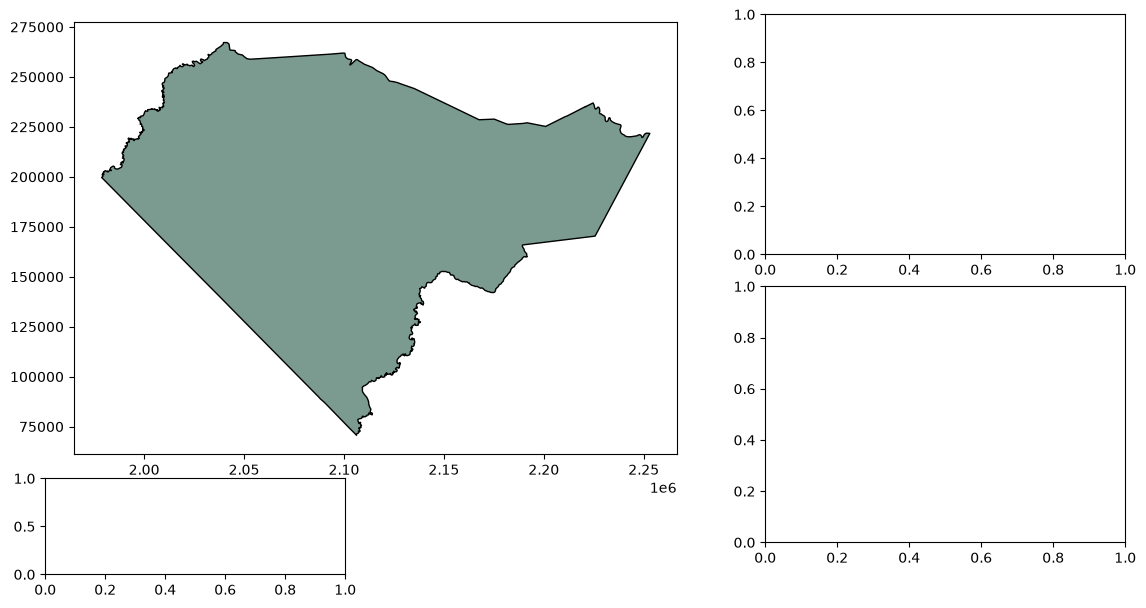

In [15]:
# This might take a few seconds and you need at least 40MB of free space in your computer
with PdfPages("NC_Counties.pdf") as pdf:  #with #manages a resource and automatically cleans up when you finish using it.
    for county in nc_counties["NAME"]:
        county_figure(county, pdf)